In [77]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


In [78]:
df = pd.read_csv('/content/heart_disease.csv')
df.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [79]:
df.tail()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
9995,25.0,Female,136.0,243.0,Medium,Yes,No,No,18.788791,Yes,...,Yes,Medium,High,6.834954,Medium,343.0,133.0,3.588814,19.132004,Yes
9996,38.0,Male,172.0,154.0,Medium,No,No,No,31.856801,Yes,...,Yes,NaN,High,8.247784,Low,377.0,83.0,2.658267,9.715709,Yes
9997,73.0,Male,152.0,201.0,High,Yes,No,Yes,26.899911,No,...,Yes,NaN,Low,4.436762,Low,248.0,88.0,4.408867,9.492429,Yes
9998,23.0,Male,142.0,299.0,Low,Yes,No,Yes,34.964026,Yes,...,Yes,Medium,High,8.526329,Medium,113.0,153.0,7.215634,11.873486,Yes
9999,38.0,Female,128.0,193.0,Medium,Yes,Yes,Yes,25.111295,No,...,Yes,High,Medium,5.659394,High,121.0,149.0,14.387810,6.208531,Yes


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption   

In [81]:
df.shape

(10000, 21)

In [82]:
df.columns

Index(['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level',
       'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI',
       'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol',
       'Alcohol Consumption', 'Stress Level', 'Sleep Hours',
       'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar',
       'CRP Level', 'Homocysteine Level', 'Heart Disease Status'],
      dtype='object')

In [83]:
df.isnull().sum()

,0
Age,29
Gender,19
Blood Pressure,19
Cholesterol Level,30
Exercise Habits,25
Smoking,25
Family Heart Disease,21
Diabetes,30
BMI,22
High Blood Pressure,26


In [84]:
df['Blood Pressure'].nunique()

61

In [85]:
df['Blood Pressure'].unique()

array([153., 146., 126., 122., 166., 152., 121., 161., 135., 144., 179.,
       134., 143., 150., 133., 173., 125., 136., 137., 139., 170., 159.,
       158., 171., 151., 163., 128., 165., 129., 168., 155., 142., 127.,
       132., 176., 141., 160., 154., 164., 138., 149., 178., 140., 147.,
        nan, 175., 162., 157., 174., 123., 145., 124., 148., 169., 172.,
       167., 131., 120., 177., 130., 180., 156.])

In [86]:
df['Cholesterol Level'].nunique()

151

In [87]:
df['Cholesterol Level'].unique()

array([155., 286., 216., 293., 242., 257., 175., 187., 291., 252., 191.,
       296., 215., 290., 255., 245., 219., 246., 268., 300., 223., 206.,
       259., 228., 185., 278., 152., 163., 183., 218., 253., 178., 197.,
       243., 266., 287., 281., 224., 177., 270., 158., 283., 272., 198.,
       240., 274., 225., 299., 298., 182., 202., 189., 167., 162., 254.,
       280., 151., 284., 292., 288., 277., 176., 170., 157., 232., 204.,
       199., 261., 295., 179., 188., 265., 289., 208., 230., 226., 221.,
       165., 229., 201., 233., 276., 247., 267., 159., 294., 238., 153.,
       169., 193., 172., 196., 244., 271., 262., 200., 241., 161., 269.,
       212., 211., 258., 195., 160., 222.,  nan, 256., 231., 263., 168.,
       273., 235., 186., 279., 282., 213., 156., 171., 236., 184., 214.,
       192., 217., 203., 210., 260., 237., 227., 190., 205., 249., 150.,
       251., 154., 297., 194., 209., 264., 174., 248., 250., 285., 173.,
       207., 234., 166., 220., 164., 275., 239., 18

In [88]:
df['Exercise Habits'].nunique()

3

In [89]:
df['Exercise Habits'].unique()

array(['High', 'Low', 'Medium', nan], dtype=object)

In [90]:
df['Gender'].nunique()

2

In [91]:
df['Gender'].unique()

array(['Male', 'Female', nan], dtype=object)

In [92]:
df['Smoking'].nunique()

2

In [93]:
df['Smoking'].unique()

array(['Yes', 'No', nan], dtype=object)

In [94]:
df['Family Heart Disease'].nunique()

2

In [95]:
df['Family Heart Disease'].unique()

array(['Yes', 'No', nan], dtype=object)

In [96]:
df['Age'].nunique()

63

In [97]:
df['Age'].unique()

array([56., 69., 46., 32., 60., 25., 78., 38., 75., 36., 40., 28., 41.,
       70., 53., 57., 20., 39., 19., 61., 47., 55., 77., 50., 29., 42.,
       66., 44., 76., 80., 59., 45., 33., 79., 64., 68., 72., 74., 54.,
       24., 26., 35., 21., 31., 67., 43., 37., 52., 34., 23., 71., 51.,
       27., 48., 65., 62., 58., 18., 22., 30., 49., 73., 63., nan])

In [98]:
df['Diabetes'].nunique()

2

In [99]:
df['Diabetes'].unique()

array(['No', 'Yes', nan], dtype=object)

In [100]:
df['Sleep Hours'].nunique()

9975

In [101]:
df['Sleep Hours'].unique()

array([7.63322838, 8.74403397, 4.44044012, ..., 4.43676208, 8.5263287 ,
       5.65939429], shape=(9976,))

In [102]:
df['High Blood Pressure'].nunique()

2

In [103]:
df['High Blood Pressure'].unique()

array(['Yes', 'No', nan], dtype=object)

In [104]:
df['Low HDL Cholesterol'].nunique()

2

In [105]:
df['Low HDL Cholesterol'].unique()

array(['Yes', 'No', nan], dtype=object)

In [106]:
df['High LDL Cholesterol'].nunique()

2

In [107]:
df['High LDL Cholesterol'].unique()

array(['No', 'Yes', nan], dtype=object)

In [108]:
df['Alcohol Consumption'].nunique()

3

In [109]:
df['Alcohol Consumption'].unique()

array(['High', 'Medium', 'Low', nan], dtype=object)

In [110]:
df['Stress Level'].nunique()

3

In [111]:
df['Stress Level'].unique()

array(['Medium', 'High', 'Low', nan], dtype=object)

In [112]:
df['BMI'].nunique()

9978

In [113]:
df['BMI'].unique()

array([24.99159109, 25.22179852, 29.85544714, ..., 26.89991089,
       34.96402562, 25.11129452], shape=(9979,))

In [114]:
df['Sugar Consumption'].nunique()

3

In [115]:
df['Sugar Consumption'].unique()

array(['Medium', 'Low', 'High', nan], dtype=object)

In [116]:
df['Triglyceride Level'].nunique()

301

In [117]:
df['Triglyceride Level'].unique()

array([342., 133., 393., 293., 263., 126., 107., 228., 317., 199., 231.,
       109., 196., 178., 343., 397., 212., 384., 346., 290., 380., 312.,
       102., 257., 180., 233., 176., 396., 179., 292., 300., 220., 341.,
       277., 248., 170., 250., 388., 120., 268., 329., 184., 377., 152.,
       378., 121., 197., 338., 187., 399., 221., 130., 110., 194., 151.,
       124., 143., 240., 118., 288., 319., 253.,  nan, 269., 278., 308.,
       224., 217., 362., 123., 116., 285., 369., 307., 375., 148., 245.,
       383., 111., 183., 296., 391., 214., 387., 249., 274., 386., 129.,
       310., 236., 222., 365., 349., 316., 283., 381., 314., 195., 229.,
       266., 360., 311., 159., 215., 139., 303., 158., 347., 227., 101.,
       140., 165., 315., 137., 128., 204., 299., 149., 167., 234., 209.,
       202., 190., 132., 389., 258., 328., 320., 279., 131., 374., 244.,
       113., 337., 203., 117., 122., 368., 331., 160., 185., 273., 340.,
       193., 255., 210., 247., 150., 213., 235., 25

In [118]:
df['Fasting Blood Sugar'].nunique()

81

In [119]:
df['Fasting Blood Sugar'].unique()

array([ nan, 157.,  92.,  94., 154.,  91.,  85., 111., 103.,  96., 139.,
       142., 102., 124., 155., 160., 132., 106., 144., 135.,  80., 116.,
       122., 146., 126., 101.,  95., 151.,  90., 104., 129.,  86.,  89.,
        84.,  82., 110., 112., 127., 134.,  99., 131.,  98.,  97., 159.,
       153., 149.,  87., 147., 114., 119., 100., 128., 130., 109., 125.,
       121., 118., 138., 140., 156., 133., 117., 141., 108., 136., 107.,
       143., 145., 152.,  88., 113., 148., 120., 150., 137.,  83.,  93.,
       105., 123., 115., 158.,  81.])

In [120]:
df['CRP Level'].nunique()

9974

In [121]:
df['CRP Level'].unique()

array([12.96924569,  9.3553894 , 12.70987253, ...,  4.40886701,
        7.21563394, 14.38780982], shape=(9975,))

In [122]:
df['Homocysteine Level'].nunique()

9980

In [123]:
df['Homocysteine Level'].unique()

array([12.3872504 , 19.29887548, 11.23092568, ...,  9.49242901,
       11.87348585,  6.20853115], shape=(9981,))

In [124]:
df['Heart Disease Status'].nunique()

2

In [125]:
df['Heart Disease Status'].unique()

array(['No', 'Yes'], dtype=object)

In [126]:
df.isnull().sum()

,0
Age,29
Gender,19
Blood Pressure,19
Cholesterol Level,30
Exercise Habits,25
Smoking,25
Family Heart Disease,21
Diabetes,30
BMI,22
High Blood Pressure,26


# Null value replacing

In [127]:
df['Age'].fillna(df['Age'].mean(),inplace=True)

/tmp/ipykernel_486/694922604.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(),inplace=True)


In [128]:
df['Cholesterol Level'].fillna(df['Cholesterol Level'].mean(),inplace=True)

/tmp/ipykernel_486/360767751.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Cholesterol Level'].fillna(df['Cholesterol Level'].mean(),inplace=True)


In [129]:
df['Blood Pressure'].fillna(df['Blood Pressure'].mean(),inplace=True)

/tmp/ipykernel_486/2529736.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Blood Pressure'].fillna(df['Blood Pressure'].mean(),inplace=True)


In [130]:
df['BMI'].fillna(df['BMI'].mean(),inplace=True)

/tmp/ipykernel_486/233936152.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['BMI'].fillna(df['BMI'].mean(),inplace=True)


In [131]:
df['Sleep Hours'].fillna(df['Sleep Hours'].mean(),inplace=True)

/tmp/ipykernel_486/1682088863.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sleep Hours'].fillna(df['Sleep Hours'].mean(),inplace=True)


In [132]:
df['Triglyceride Level'].fillna(df['Triglyceride Level'].mean(),inplace=True)

/tmp/ipykernel_486/937398287.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Triglyceride Level'].fillna(df['Triglyceride Level'].mean(),inplace=True)


In [133]:
df['Fasting Blood Sugar'].fillna(df['Fasting Blood Sugar'].mean(),inplace=True)

/tmp/ipykernel_486/1181605345.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Fasting Blood Sugar'].fillna(df['Fasting Blood Sugar'].mean(),inplace=True)


In [134]:
df['CRP Level'].fillna(df['CRP Level'].mean(),inplace=True)

/tmp/ipykernel_486/4217688541.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['CRP Level'].fillna(df['CRP Level'].mean(),inplace=True)


In [135]:
df['Homocysteine Level'].fillna(df['Homocysteine Level'].mean(),inplace=True)

/tmp/ipykernel_486/1609534524.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Homocysteine Level'].fillna(df['Homocysteine Level'].mean(),inplace=True)


In [136]:
df.isnull().sum()

,0
Age,0
Gender,19
Blood Pressure,0
Cholesterol Level,0
Exercise Habits,25
Smoking,25
Family Heart Disease,21
Diabetes,30
BMI,0
High Blood Pressure,26


In [137]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   10000 non-null  float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        10000 non-null  float64
 3   Cholesterol Level     10000 non-null  float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   10000 non-null  float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           10000 non-null  float64
 15  Sugar Consumption   

In [138]:
df['Gender'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/1377688136.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Gender'].fillna('unknown',inplace=True)


In [139]:
df['Exercise Habits'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/582149064.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Exercise Habits'].fillna('unknown',inplace=True)


In [140]:
df['Smoking'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/3193634811.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Smoking'].fillna('unknown',inplace=True)


In [141]:
df['Family Heart Disease'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/2936531761.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Family Heart Disease'].fillna('unknown',inplace=True)


In [142]:
df['Diabetes'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/3987651553.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Diabetes'].fillna('unknown',inplace=True)


In [143]:
df['High Blood Pressure'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/1903558909.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['High Blood Pressure'].fillna('unknown',inplace=True)


In [144]:
df['Low HDL Cholesterol'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/1751932044.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Low HDL Cholesterol'].fillna('unknown',inplace=True)


In [145]:
df['High LDL Cholesterol'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/2283927082.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['High LDL Cholesterol'].fillna('unknown',inplace=True)


In [146]:
df['Alcohol Consumption'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/3607085355.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Alcohol Consumption'].fillna('unknown',inplace=True)


In [147]:
df['Stress Level'].fillna('Stress Level',inplace=True)

/tmp/ipykernel_486/1524246480.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Stress Level'].fillna('Stress Level',inplace=True)


In [148]:
df['Sugar Consumption'].fillna('unknown',inplace=True)

/tmp/ipykernel_486/32361705.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sugar Consumption'].fillna('unknown',inplace=True)


In [156]:
df.isnull().sum()

,0
Age,0
Gender,0
Blood Pressure,0
Cholesterol Level,0
Exercise Habits,0
Smoking,0
Family Heart Disease,0
Diabetes,0
BMI,0
High Blood Pressure,0


In [149]:
df.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,120.142213,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.000000,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.000000,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.000000,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.000000,10.381259,8.153887,No


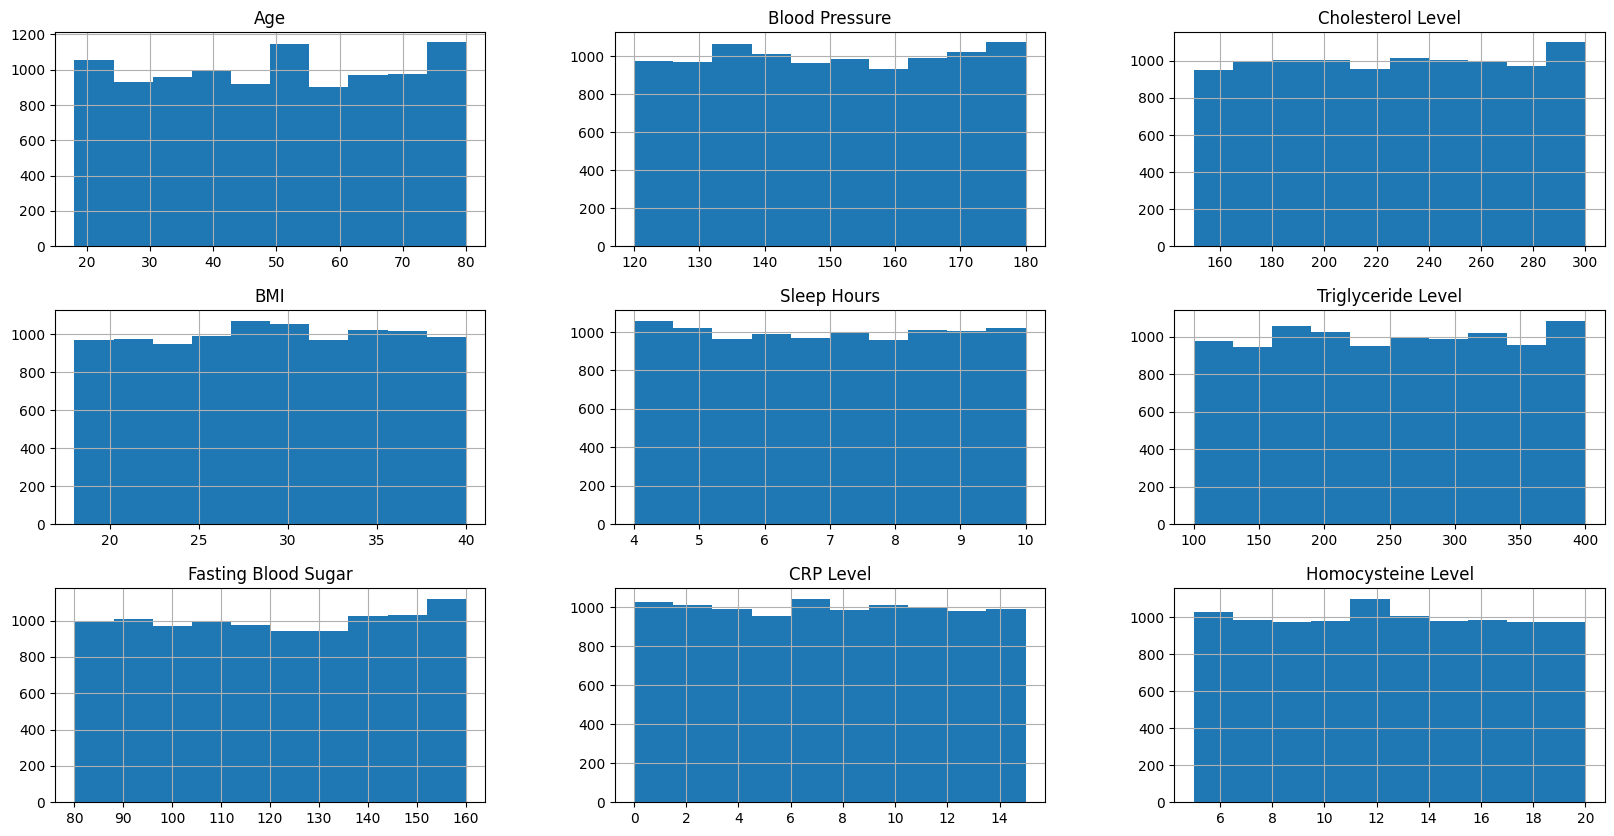

In [161]:
df.hist(figsize=(20,10))
plt.show()

In [151]:
df.sample(3)

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
8191,26.0,Female,121.0,191.0,High,Yes,No,Yes,22.796538,Yes,...,Yes,Low,Medium,7.541241,Low,199.0,96.0,1.526057,15.999742,Yes
8529,60.0,Male,163.0,297.0,Medium,No,No,Yes,29.395418,No,...,Yes,High,Low,8.394086,High,320.0,146.0,3.717189,14.165027,Yes
2455,61.0,Female,152.0,259.0,Medium,No,Yes,Yes,26.036053,No,...,No,High,Low,4.813106,High,184.0,101.0,12.364077,15.603546,No


In [152]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   10000 non-null  float64
 1   Gender                10000 non-null  object 
 2   Blood Pressure        10000 non-null  float64
 3   Cholesterol Level     10000 non-null  float64
 4   Exercise Habits       10000 non-null  object 
 5   Smoking               10000 non-null  object 
 6   Family Heart Disease  10000 non-null  object 
 7   Diabetes              10000 non-null  object 
 8   BMI                   10000 non-null  float64
 9   High Blood Pressure   10000 non-null  object 
 10  Low HDL Cholesterol   10000 non-null  object 
 11  High LDL Cholesterol  10000 non-null  object 
 12  Alcohol Consumption   10000 non-null  object 
 13  Stress Level          10000 non-null  object 
 14  Sleep Hours           10000 non-null  float64
 15  Sugar Consumption   

In [154]:
df.describe()

,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,49.296259,149.757740,225.425577,29.077269,6.991329,250.734409,120.142213,7.472201,12.456271
std,18.167567,17.556265,43.510390,6.300156,1.751002,86.953954,23.558052,4.334601,4.319100
min,18.000000,120.000000,150.000000,18.002837,4.000605,100.000000,80.000000,0.003647,5.000236
25%,34.000000,134.000000,187.000000,23.668887,5.455288,176.000000,99.000000,3.681800,8.729771
50%,49.000000,150.000000,225.425577,29.077269,6.996016,250.734409,120.000000,7.472201,12.421274
75%,65.000000,165.000000,263.000000,34.509009,8.527938,326.000000,141.000000,11.244879,16.130968
max,80.000000,180.000000,300.000000,39.996954,9.999952,400.000000,160.000000,14.997087,19.999037


In [153]:
df.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,120.142213,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.000000,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.000000,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.000000,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.000000,10.381259,8.153887,No


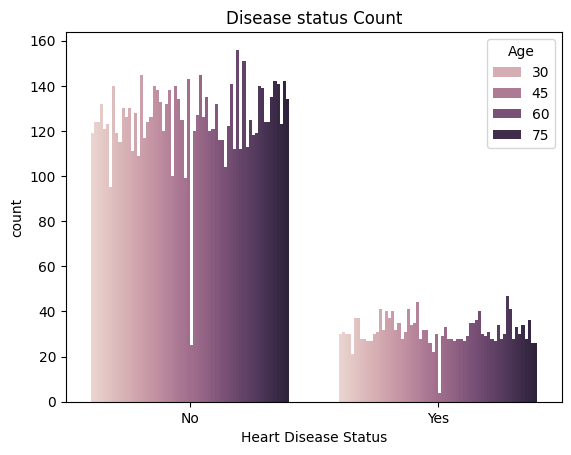

In [163]:
sns.countplot(x='Heart Disease Status' , hue='Age',data=df)
plt.title('Disease status Count')
plt.show()

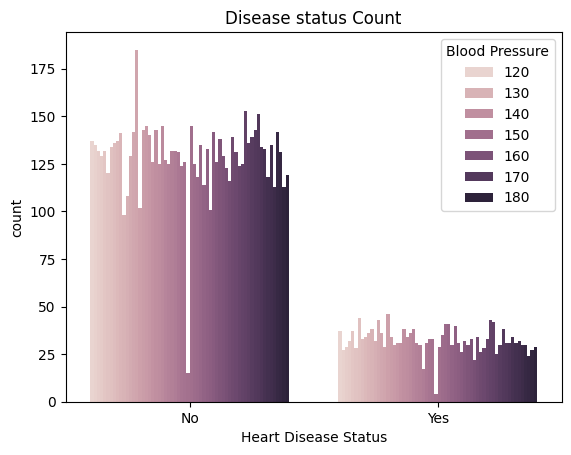

In [164]:
sns.countplot(x='Heart Disease Status' , hue='Blood Pressure',data=df)
plt.title('Disease status Count')
plt.show()

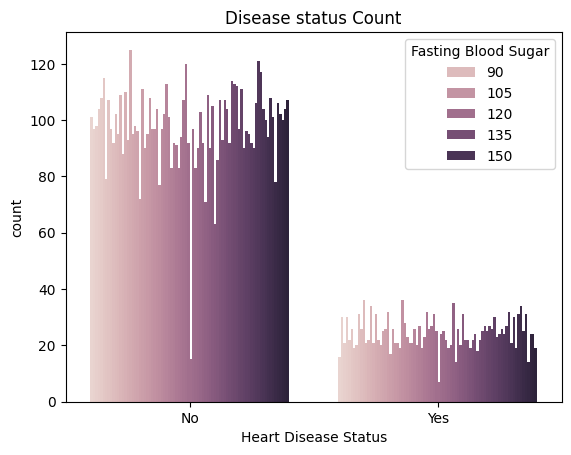

In [165]:
sns.countplot(x='Heart Disease Status' , hue='Fasting Blood Sugar',data=df)
plt.title('Disease status Count')
plt.show()

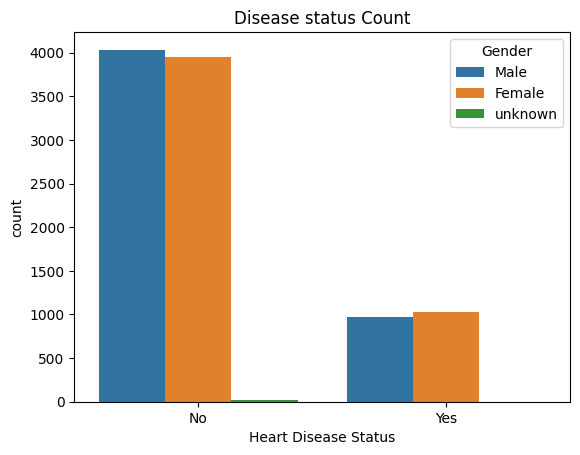

In [166]:
sns.countplot(x='Heart Disease Status' , hue='Gender',data=df)
plt.title('Disease status Count')
plt.show()

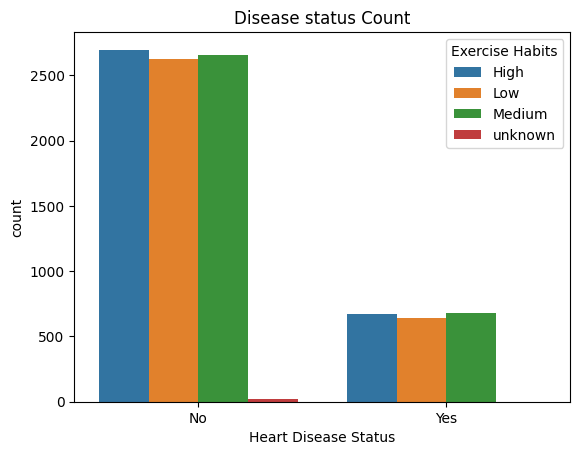

In [168]:
sns.countplot(x='Heart Disease Status' , hue='Exercise Habits',data=df)
plt.title('Disease status Count')
plt.show()

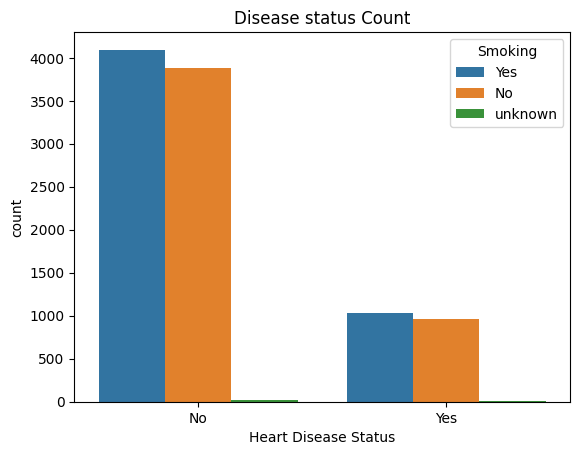

In [169]:
sns.countplot(x='Heart Disease Status' , hue='Smoking',data=df)
plt.title('Disease status Count')
plt.show()

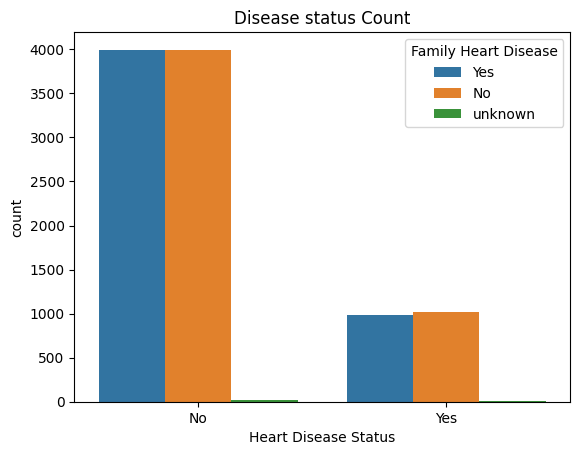

In [170]:
sns.countplot(x='Heart Disease Status' , hue='Family Heart Disease',data=df)
plt.title('Disease status Count')
plt.show()

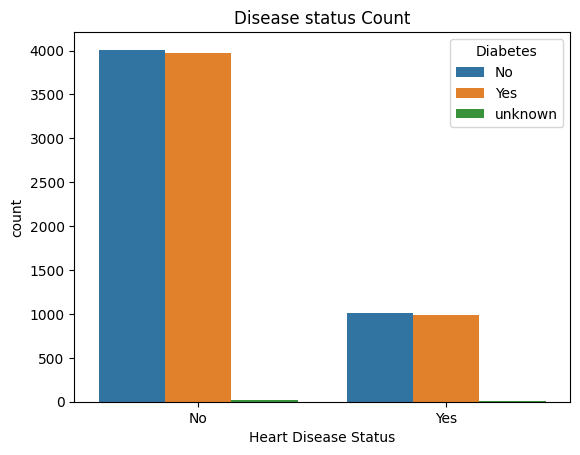

In [171]:
sns.countplot(x='Heart Disease Status' , hue='Diabetes',data=df)
plt.title('Disease status Count')
plt.show()

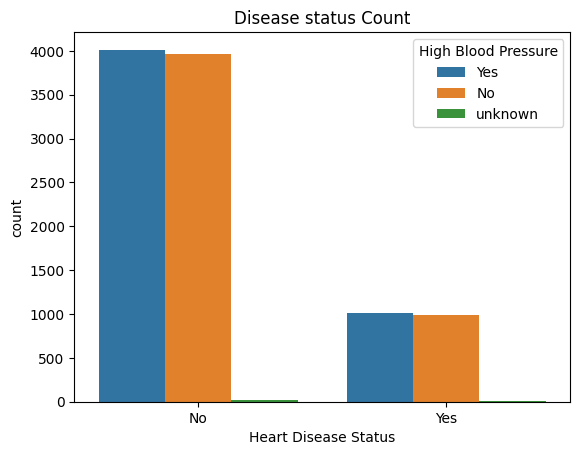

In [172]:
sns.countplot(x='Heart Disease Status' , hue='High Blood Pressure',data=df)
plt.title('Disease status Count')
plt.show()

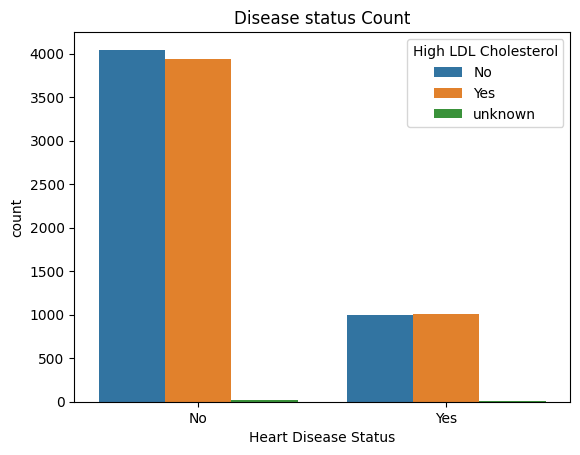

In [173]:
sns.countplot(x='Heart Disease Status' , hue='High LDL Cholesterol',data=df)
plt.title('Disease status Count')
plt.show()

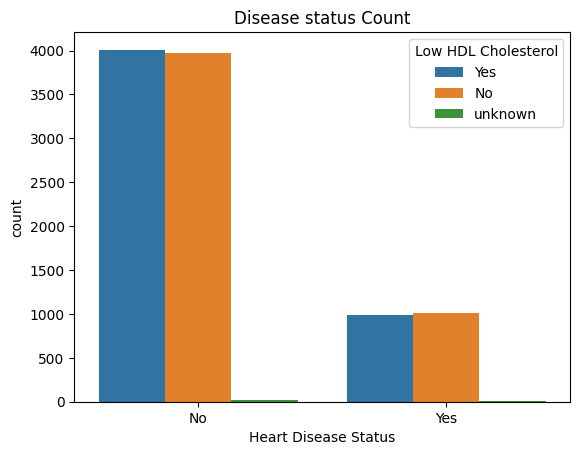

In [174]:
sns.countplot(x='Heart Disease Status' , hue='Low HDL Cholesterol',data=df)
plt.title('Disease status Count')
plt.show()

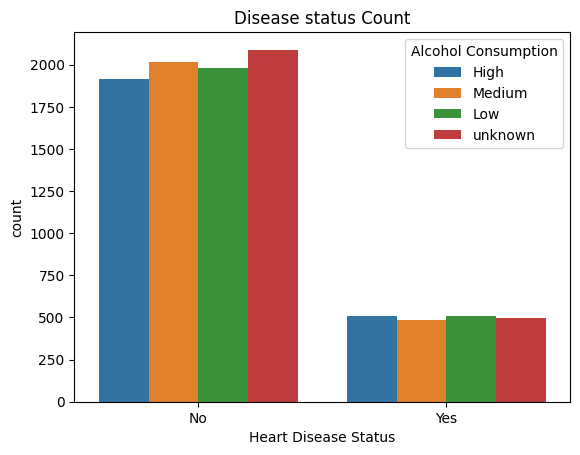

In [175]:
sns.countplot(x='Heart Disease Status' , hue='Alcohol Consumption',data=df)
plt.title('Disease status Count')
plt.show()

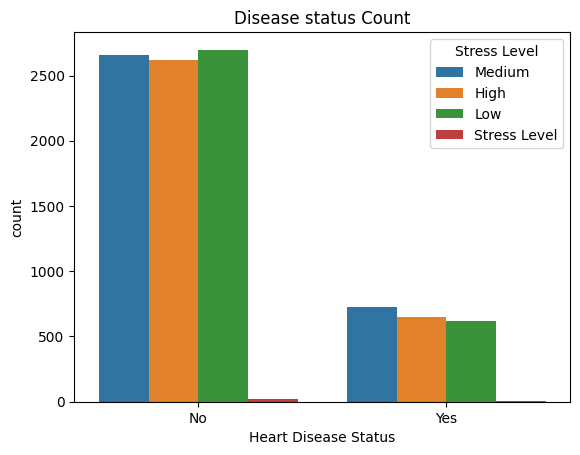

In [176]:
sns.countplot(x='Heart Disease Status' , hue='Stress Level',data=df)
plt.title('Disease status Count')
plt.show()

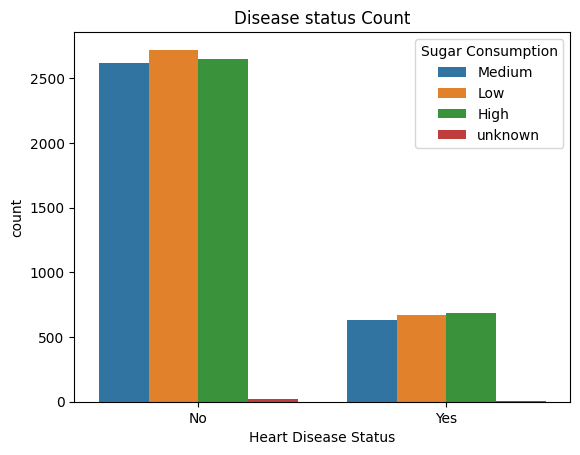

In [177]:
sns.countplot(x='Heart Disease Status' , hue='Sugar Consumption',data=df)
plt.title('Disease status Count')
plt.show()

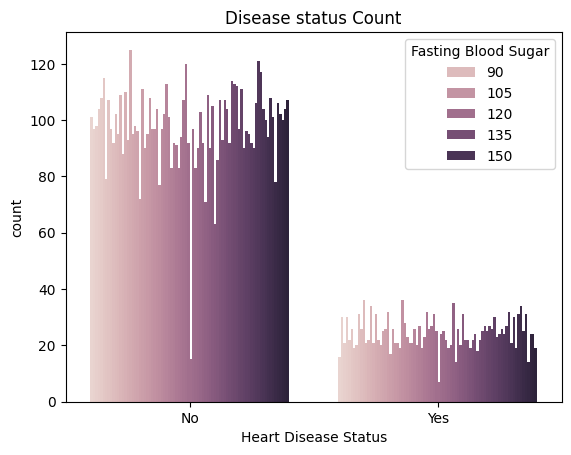

In [178]:
sns.countplot(x='Heart Disease Status' , hue='Fasting Blood Sugar',data=df)
plt.title('Disease status Count')
plt.show()